In [1]:
import pandas as pd
import numpy as np

# Load processed dataset
df = pd.read_csv("../data/ipl_score_prediction.csv")

print("Dataset Shape:", df.shape)

display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (213, 6)


,Match_ID,Innings,Overs,Current_Runs,Wickets,Final_Runs
0,1,1,5,33,3,201
1,1,1,10,87,3,201
2,1,1,15,142,5,201
3,2,1,5,68,0,220
4,2,1,10,120,2,220



Missing Values:
Match_ID        0
Innings         0
Overs           0
Current_Runs    0
Wickets         0
Final_Runs      0
dtype: int64


STATISTICAL SUMMARY


,Match_ID,Innings,Overs,Current_Runs,Wickets,Final_Runs
count,213.000000,213.0,213.0000,213.000000,213.000000,213.000000
mean,38.028169,1.0,10.0000,95.117371,2.525822,195.774648
std,21.391216,0.0,4.0921,44.725160,1.755192,36.536954
min,1.000000,1.0,5.0000,11.000000,0.000000,75.000000
25%,20.000000,1.0,5.0000,58.000000,1.000000,163.000000
50%,38.000000,1.0,10.0000,93.000000,2.000000,201.000000
75%,57.000000,1.0,15.0000,127.000000,4.000000,222.000000
max,74.000000,1.0,15.0000,207.000000,8.000000,264.000000


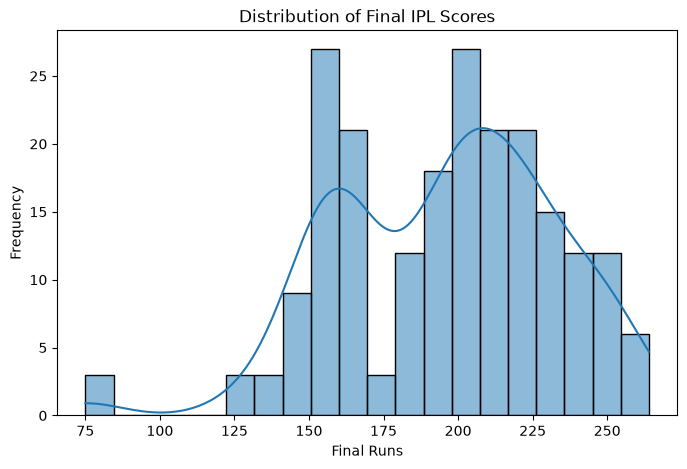

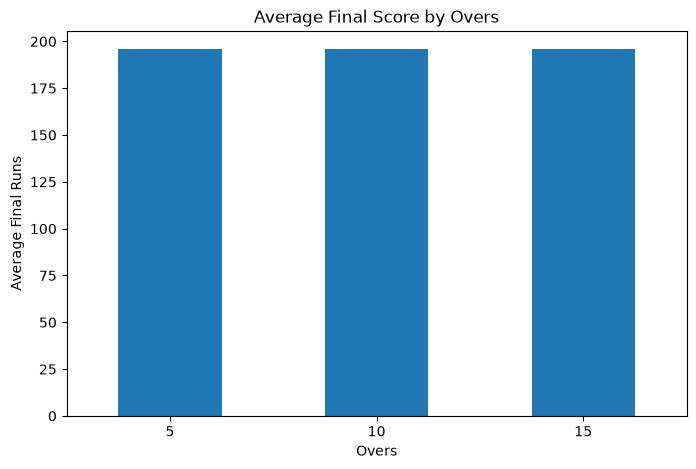

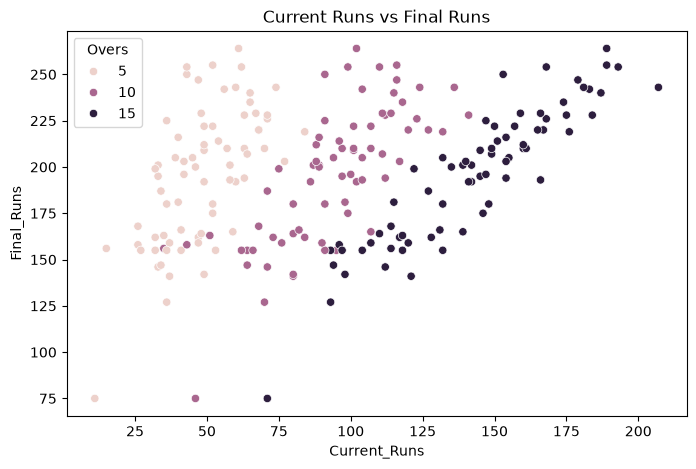

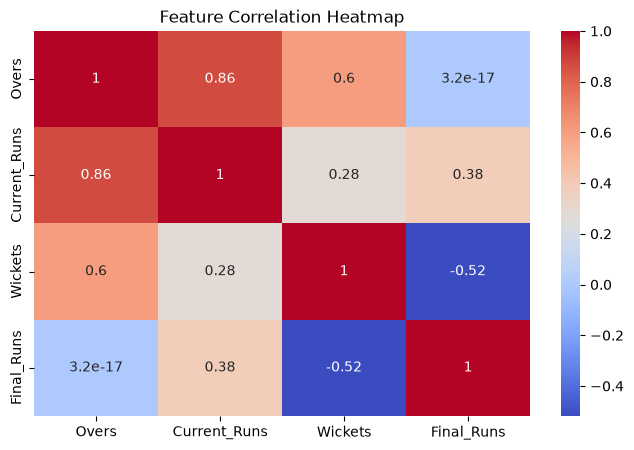

In [2]:
# STEP 2: Exploratory Data Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Basic statistical information
print("STATISTICAL SUMMARY")
display(df.describe())

# Distribution of final scores
plt.figure(figsize=(8, 5))
sns.histplot(df["Final_Runs"], bins=20, kde=True)
plt.title("Distribution of Final IPL Scores")
plt.xlabel("Final Runs")
plt.ylabel("Frequency")
plt.show()

# Average final score at different checkpoints
average_scores = df.groupby("Overs")["Final_Runs"].mean()

plt.figure(figsize=(8, 5))
average_scores.plot(kind="bar")
plt.title("Average Final Score by Overs")
plt.xlabel("Overs")
plt.ylabel("Average Final Runs")
plt.xticks(rotation=0)
plt.show()

# Current runs vs final runs
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Current_Runs",
    y="Final_Runs",
    hue="Overs"
)
plt.title("Current Runs vs Final Runs")
plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(
    df[["Overs", "Current_Runs", "Wickets", "Final_Runs"]].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Feature Correlation Heatmap")
plt.show()

In [3]:
# STEP 3: Linear Regression Model

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Select input features
X = df[["Overs", "Current_Runs", "Wickets"]]

# Select target variable
y = df["Final_Runs"]

# Match IDs will be used only for splitting
groups = df["Match_ID"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (213, 3)
Target shape: (213,)


In [5]:
# Split data by match ID

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training matches:", groups.iloc[train_idx].nunique())
print("Testing matches:", groups.iloc[test_idx].nunique())

Training samples: 168
Testing samples: 45
Training matches: 56
Testing matches: 15


In [6]:
# Create Linear Regression model

linear_model = LinearRegression()

# Train model
linear_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [7]:
# Predict final scores

y_pred = linear_model.predict(X_test)

# Display actual vs predicted scores

results = pd.DataFrame({
    "Actual_Score": y_test.values,
    "Predicted_Score": y_pred.round(2)
})

display(results.head(15))

,Actual_Score,Predicted_Score
0,201,166.13
1,201,183.20
2,201,185.63
3,141,185.61
4,141,160.82
5,141,157.52
6,226,226.28
7,226,210.19
8,226,218.57
9,156,148.73


In [8]:
# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION PERFORMANCE")
print("--------------------------------")

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

LINEAR REGRESSION PERFORMANCE
--------------------------------
MAE: 16.41
MSE: 440.09
RMSE: 20.98
R2 Score: 0.5452


In [ ]:
# Create Linear Regression model

linear_model = LinearRegression()

# Train model
linear_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


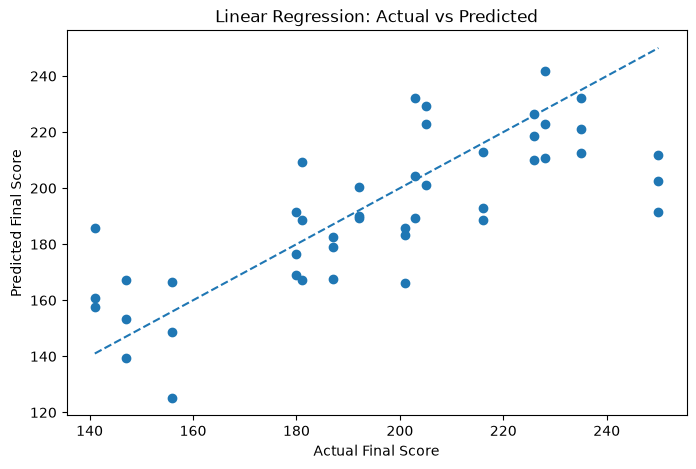

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")

plt.title("Linear Regression: Actual vs Predicted")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [10]:
# Convert final scores into binary classes

y_train_class = (y_train >= 200).astype(int)
y_test_class = (y_test >= 200).astype(int)

print("Training class distribution:")
print(y_train_class.value_counts())

print("\nTesting class distribution:")
print(y_test_class.value_counts())

Training class distribution:
Final_Runs
1    87
0    81
Name: count, dtype: int64

Testing class distribution:
Final_Runs
1    24
0    21
Name: count, dtype: int64


In [12]:
# Create Logistic Regression pipeline

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

# Train model

logistic_model.fit(X_train, y_train_class)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [13]:
# Predict high or low scores

y_class_pred = logistic_model.predict(X_test)

results_logistic = pd.DataFrame({
    "Actual_Class": y_test_class.values,
    "Predicted_Class": y_class_pred
})

display(results_logistic.head(15))

,Actual_Class,Predicted_Class
0,1,0
1,1,0
2,1,0
3,0,0
4,0,0
5,0,0
6,1,1
7,1,1
8,1,1
9,0,0


In [14]:
accuracy = accuracy_score(y_test_class, y_class_pred)

print("LOGISTIC REGRESSION PERFORMANCE")
print("--------------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test_class,
    y_class_pred,
    target_names=["Low Score", "High Score"],
    zero_division=0
))

LOGISTIC REGRESSION PERFORMANCE
--------------------------------
Accuracy: 80.0 %

Classification Report:
              precision    recall  f1-score   support

   Low Score       0.73      0.90      0.81        21
  High Score       0.89      0.71      0.79        24

    accuracy                           0.80        45
   macro avg       0.81      0.81      0.80        45
weighted avg       0.82      0.80      0.80        45



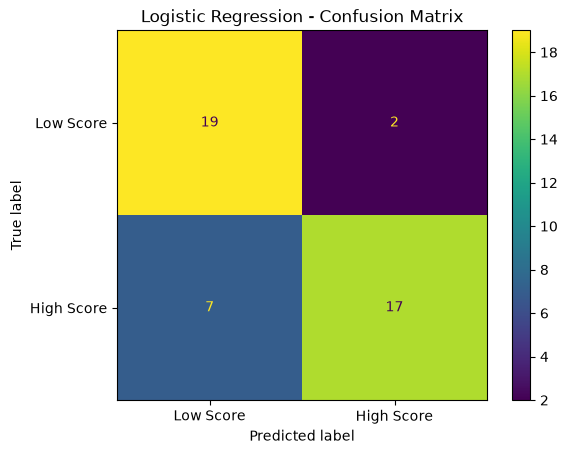

In [15]:
cm = confusion_matrix(y_test_class, y_class_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Score", "High Score"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [16]:
# FEATURE ENGINEERING

X_train_improved = X_train.copy()
X_test_improved = X_test.copy()

# Create new features for training data
X_train_improved["Run_Rate"] = (
    X_train_improved["Current_Runs"] /
    X_train_improved["Overs"]
)

X_train_improved["Wickets_Remaining"] = (
    10 - X_train_improved["Wickets"]
)

X_train_improved["Balls_Remaining"] = (
    120 - X_train_improved["Overs"] * 6
)

X_train_improved["Runs_Per_Wicket"] = (
    X_train_improved["Current_Runs"] /
    (10 - X_train_improved["Wickets"]).clip(lower=1)
)

# Create the same features for testing data
X_test_improved["Run_Rate"] = (
    X_test_improved["Current_Runs"] /
    X_test_improved["Overs"]
)

X_test_improved["Wickets_Remaining"] = (
    10 - X_test_improved["Wickets"]
)

X_test_improved["Balls_Remaining"] = (
    120 - X_test_improved["Overs"] * 6
)

X_test_improved["Runs_Per_Wicket"] = (
    X_test_improved["Current_Runs"] /
    (10 - X_test_improved["Wickets"]).clip(lower=1)
)

print("Original Features:", X_train.shape[1])
print("Improved Features:", X_train_improved.shape[1])

print("\nNew Training Shape:", X_train_improved.shape)
print("New Testing Shape:", X_test_improved.shape)

display(X_train_improved.head())

Original Features: 3
Improved Features: 7

New Training Shape: (168, 7)
New Testing Shape: (45, 7)


,Overs,Current_Runs,Wickets,Run_Rate,Wickets_Remaining,Balls_Remaining,Runs_Per_Wicket
3,5,68,0,13.600000,10,90,6.800000
4,10,120,2,12.000000,8,60,15.000000
5,15,167,3,11.133333,7,30,23.857143
6,5,36,3,7.200000,7,90,5.142857
7,10,70,6,7.000000,4,60,17.500000


In [17]:
# Train improved Linear Regression

linear_model_improved = LinearRegression()

linear_model_improved.fit(
    X_train_improved,
    y_train
)

# Make predictions
y_pred_improved = linear_model_improved.predict(
    X_test_improved
)

print("Improved Linear Regression Trained Successfully!")

Improved Linear Regression Trained Successfully!


In [18]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

mae_new = mean_absolute_error(y_test, y_pred_improved)

mse_new = mean_squared_error(y_test, y_pred_improved)

rmse_new = np.sqrt(mse_new)

r2_new = r2_score(y_test, y_pred_improved)

print("IMPROVED LINEAR REGRESSION")
print("-------------------------")
print("MAE:", round(mae_new, 2))
print("MSE:", round(mse_new, 2))
print("RMSE:", round(rmse_new, 2))
print("R2 Score:", round(r2_new, 4))

IMPROVED LINEAR REGRESSION
-------------------------
MAE: 16.99
MSE: 465.67
RMSE: 21.58
R2 Score: 0.5188


In [19]:
logistic_model_improved = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model_improved.fit(
    X_train_improved,
    y_train_class
)

y_class_pred_improved = logistic_model_improved.predict(
    X_test_improved
)

print("Improved Logistic Regression Trained Successfully!")

Improved Logistic Regression Trained Successfully!


In [20]:
accuracy_new = accuracy_score(
    y_test_class,
    y_class_pred_improved
)

print("IMPROVED LOGISTIC REGRESSION")
print("---------------------------")
print("Accuracy:", round(accuracy_new * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(
    y_test_class,
    y_class_pred_improved,
    target_names=["Low Score", "High Score"]
))

IMPROVED LOGISTIC REGRESSION
---------------------------
Accuracy: 82.22 %

Classification Report:
              precision    recall  f1-score   support

   Low Score       0.76      0.90      0.83        21
  High Score       0.90      0.75      0.82        24

    accuracy                           0.82        45
   macro avg       0.83      0.83      0.82        45
weighted avg       0.83      0.82      0.82        45



In [21]:
comparison = pd.DataFrame({
    "Model": ["Original", "Improved"],
    "Linear Regression R2": [
        0.5452,
        r2_new
    ],
    "Logistic Regression Accuracy": [
        80.0,
        accuracy_new * 100
    ]
})

display(comparison)

,Model,Linear Regression R2,Logistic Regression Accuracy
0,Original,0.545200,80.000000
1,Improved,0.518798,82.222222


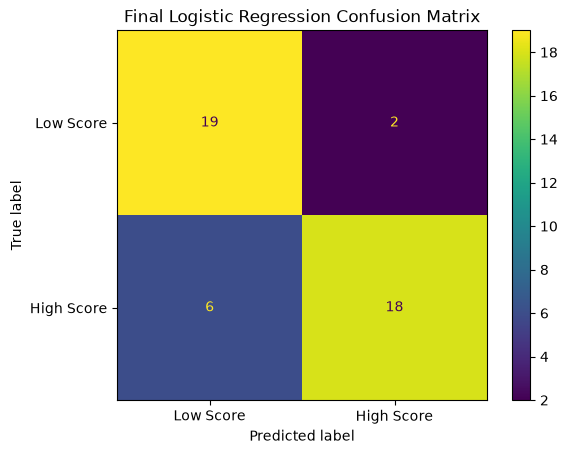

In [22]:
# Final Confusion Matrix - Improved Logistic Regression

cm = confusion_matrix(
    y_test_class,
    y_class_pred_improved
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Score", "High Score"]
)

disp.plot()
plt.title("Final Logistic Regression Confusion Matrix")
plt.show()

In [23]:
# Final Model Comparison

regression_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression (Original)",
        "Linear Regression (Improved)"
    ],
    "MAE": [mae, mae_new],
    "RMSE": [rmse, rmse_new],
    "R2 Score": [r2, r2_new]
})

classification_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (Original)",
        "Logistic Regression (Improved)"
    ],
    "Accuracy (%)": [
        accuracy * 100,
        accuracy_new * 100
    ]
})

print("REGRESSION MODEL COMPARISON")
display(regression_comparison)

print("CLASSIFICATION MODEL COMPARISON")
display(classification_comparison)

REGRESSION MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
0,Linear Regression (Original),16.410567,20.97829,0.545229
1,Linear Regression (Improved),16.989708,21.57930,0.518798


CLASSIFICATION MODEL COMPARISON


,Model,Accuracy (%)
0,Logistic Regression (Original),80.000000
1,Logistic Regression (Improved),82.222222
